# GPT-6.1 Terra Zero-Shot Evaluation

## 1. Model & Experiment Overview

GPT-6.1 Terra, recorded as `gpt-6.1-terra`, classified math word problems as `ANSWERABLE` or `UNANSWERABLE` using the original frozen zero-shot prompt. The experiments used OpenAI's hosted Chat Completions API. The model runtime was provider-managed, so local GPU, dtype, and tokenizer settings do not apply.

This notebook reads the completed `run_01` artifacts for SUM Test and UMWP under `results/api/openai/gpt-6.1-terra/`. The analysis uses the saved metrics, predictions, confusion matrices, and API usage metadata.

In [1]:
import hashlib
import json
import math
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

PROJECT_ROOT = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / 'notebooks').is_dir() and (path / 'results/api/openai').is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Start from the CDS1092 project root or notebooks directory.')

RESULTS_DIR = PROJECT_ROOT / 'results/api/openai/gpt-6.1-terra'
RUN_ID = 'run_01'
LABELS = ['ANSWERABLE', 'UNANSWERABLE']
PREDICTED_LABELS = [*LABELS, 'INVALID']
METRICS = {
    'Accuracy': 'accuracy',
    'Precision (UNANSWERABLE)': 'precision_unanswerable',
    'Recall (UNANSWERABLE)': 'recall_unanswerable',
    'F1 (UNANSWERABLE)': 'f1_unanswerable',
}
plt.rcParams.update({'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})


def load_evaluation(dataset, expected_examples, identifier):
    directory = RESULTS_DIR / dataset / RUN_ID
    metrics = json.loads((directory / 'metrics.json').read_text(encoding='utf-8'))
    matrix = pd.read_csv(directory / 'confusion_matrix.csv', index_col='true_label')
    run = metrics['run']
    metadata = json.loads((directory / 'run_metadata.json').read_text(encoding='utf-8'))
    if (not metadata['all_rows_received'] or run['limit'] is not None
            or any(metadata[key] != value for key, value in run.items())):
        raise ValueError(f'{directory}: incomplete run or inconsistent metadata')
    if hashlib.sha256(run['prompt'].encode('utf-8')).hexdigest() != run['prompt_sha256']:
        raise ValueError(f'{directory}: saved prompt fingerprint does not match')
    usage = metadata['usage']
    if (usage['completed_requests'] != expected_examples
            or sum(usage['attempts_by_state'].values()) != usage['request_attempts']
            or sum(usage['finish_reasons'].values()) != usage['completed_requests']
            or usage['input_tokens'] + usage['output_tokens'] != usage['total_tokens']):
        raise ValueError(f'{directory}: inconsistent request or token totals')
    predictions = pd.read_csv(
        directory / 'predictions.csv', keep_default_na=False,
        dtype={identifier: str, 'raw_response': str, 'text': str},
    )
    expected_columns = {'row_index', identifier, 'text', 'true_label',
                        'raw_response', 'prediction', 'valid', 'hit_token_limit'}
    if not expected_columns.issubset(predictions):
        raise ValueError(f'{directory}: predictions CSV lacks required columns')
    if (predictions['row_index'].tolist() != list(range(expected_examples))
            or predictions[identifier].eq('').any()
            or not predictions['true_label'].isin(LABELS).all()
            or not predictions['prediction'].isin(PREDICTED_LABELS).all()
            or not predictions['valid'].eq(predictions['prediction'].ne('INVALID')).all()
            or predictions['hit_token_limit'].sum() != usage['finish_reasons'].get('length', 0)):
        raise ValueError(f'{directory}: unexpected prediction rows or labels')
    parsed = predictions['raw_response'].str.strip()
    parsed = parsed.where(parsed.isin(LABELS), 'INVALID')
    if not parsed.eq(predictions['prediction']).all():
        raise ValueError(f'{directory}: raw responses and recorded labels disagree')
    reconstructed = pd.crosstab(predictions['true_label'], predictions['prediction']).reindex(
        index=LABELS, columns=PREDICTED_LABELS, fill_value=0,
    )
    if reconstructed.values.tolist() != matrix.values.tolist():
        raise ValueError(f'{directory}: prediction counts disagree with the matrix')

    if run['model_id'] != 'gpt-6.1-terra':
        raise ValueError(f'{directory}: unexpected model identity')
    if (run['dataset'], run['run_id'], metrics['positive_class']) != (dataset, RUN_ID, LABELS[1]):
        raise ValueError(f'{directory}: unexpected run identity or positive class')
    if (list(matrix.index) != LABELS or list(matrix.columns) != PREDICTED_LABELS
            or metrics['confusion_matrix_rows'] != LABELS
            or metrics['confusion_matrix_columns'] != PREDICTED_LABELS):
        raise ValueError(f'{directory}: unexpected matrix labels or order')
    if (not all(pd.api.types.is_integer_dtype(dtype) for dtype in matrix.dtypes)
            or (matrix < 0).any().any() or matrix.values.tolist() != metrics['confusion_matrix']):
        raise ValueError(f'{directory}: CSV and JSON confusion counts disagree or are invalid')
    if not (matrix.values.sum() == metrics['num_examples'] == run['row_count'] == expected_examples):
        raise ValueError(f'{directory}: unexpected number of examples')

    tn, fp, invalid_negative = matrix.loc[LABELS[0]]
    fn, tp, invalid_positive = matrix.loc[LABELS[1]]
    missed = fn + invalid_positive

    def ratio(numerator, denominator):
        return numerator / denominator if denominator else 0.0

    expected = {
        'accuracy': (tn + tp) / expected_examples,
        'precision_unanswerable': ratio(tp, tp + fp),
        'recall_unanswerable': ratio(tp, tp + missed),
        'f1_unanswerable': ratio(2 * tp, 2 * tp + fp + missed),
        'num_invalid': invalid_negative + invalid_positive,
        'invalid_rate': (invalid_negative + invalid_positive) / expected_examples,
    }
    for key, value in expected.items():
        if not math.isclose(metrics[key], value, rel_tol=0, abs_tol=1e-12):
            raise ValueError(f'{directory}: {key} disagrees with the saved confusion counts')
    return metrics, matrix, predictions, metadata


sum_metrics, sum_matrix, sum_predictions, sum_metadata = load_evaluation('sum', 10944, 'pair_id')
umwp_metrics, umwp_matrix, umwp_predictions, umwp_metadata = load_evaluation('umwp', 5200, 'id')

In [2]:
run = sum_metadata
shared_settings = (
    'model_id', 'endpoint', 'openai_sdk_version', 'parameters', 'prompt_version', 'prompt',
    'prompt_sha256', 'invalid_output_policy', 'prices_usd_per_million', 'pricing_verified_date',
)
if any(run[key] != umwp_metadata[key] for key in shared_settings):
    raise ValueError('Saved runs disagree on the shared API configuration.')

parameters = run['parameters']
configuration = {
    'Requested API model': run['model_id'],
    'Endpoint': run['endpoint'],
    'OpenAI SDK': run['openai_sdk_version'],
    'Prompt version': run['prompt_version'],
    'Reasoning effort': parameters['reasoning_effort'],
    'Temperature': parameters['temperature'],
    'Maximum completion tokens': parameters['max_completion_tokens'],
    'Service tier request': parameters['service_tier'],
    'API store parameter': parameters['store'],
}
display(pd.Series(configuration, name='Recorded setting').rename_axis('Setting').to_frame())
display(Markdown('**Exact prompt**\n\n```text\n' + run['prompt'] + '\n```'))

metadata = {'SUM Test': sum_metadata, 'UMWP': umwp_metadata}
matrices = {'SUM Test': sum_matrix, 'UMWP': umwp_matrix}
dataset_table = pd.DataFrame.from_dict({
    name: {
        'Examples': record['row_count'],
        **{label: f'{matrix.loc[label].sum():,} ({matrix.loc[label].sum() / record["row_count"]:.2%})'
           for label in LABELS},
        'Returned API model': ', '.join(record['usage']['returned_models']),
        'Started (UTC)': record['started_at_utc'],
    }
    for name, record in metadata.items() for matrix in [matrices[name]]
}, orient='index').rename_axis('Dataset')
display(dataset_table)

fingerprints = {
    'Prompt SHA-256': run['prompt_sha256'],
    **{f'{name} dataset SHA-256 ({record["run_id"]})': record['dataset_sha256']
       for name, record in metadata.items()},
}
display(pd.Series(fingerprints, name='Recorded value').rename_axis('Fingerprint').to_frame())

,Recorded setting
Setting,
Requested API model,gpt-6.1-terra
Endpoint,POST /v1/chat/completions
OpenAI SDK,2.54.0
Prompt version,original_frozen_zero_shot
Reasoning effort,none
Temperature,0
Maximum completion tokens,16
Service tier request,default
API store parameter,False


**Exact prompt**

```text
Determine whether the following math problem can be answered using the information provided.

Respond with exactly one label:
ANSWERABLE or UNANSWERABLE.

Do not solve the problem or provide an explanation.

Math problem:
{question}

Label:
```

,Examples,ANSWERABLE,UNANSWERABLE,Returned API model,Started (UTC)
Dataset,,,,,
SUM Test,10944,"5,472 (50.00%)","5,472 (50.00%)",gpt-6.1-terra,2026-11-22T11:13:50+00:00
UMWP,5200,"2,600 (50.00%)","2,600 (50.00%)",gpt-6.1-terra,2026-11-22T09:45:29+00:00


,Recorded value
Fingerprint,
Prompt SHA-256,0f38d949358979147c7d89f8c1e4635c9608de88a47fe2...
SUM Test dataset SHA-256 (run_01),c1e4bac1e1d1f27ab8a6408ac68ae710faf521822bff49...
UMWP dataset SHA-256 (run_01),92df3bed2d3cee139c6ddbca2673fca0a1687aa9f90b3c...


## 2. Evaluation Metrics

**UNANSWERABLE is the positive class.**

- **Accuracy** is the fraction of all questions assigned the correct label.
- **Precision** is the fraction of predicted UNANSWERABLE questions that are truly unanswerable.
- **Recall** is the fraction of truly unanswerable questions detected by the model.
- **F1** is the harmonic mean of precision and recall for UNANSWERABLE.

Confusion matrices show actual labels in rows and predicted labels in columns. A false positive flags an answerable question as unanswerable. A false negative marks an unanswerable question as answerable, which can lead a downstream solver to attempt a question with insufficient information. The INVALID column tracks responses outside the two permitted labels. Each heatmap scales its colors to its own counts.

The request used temperature zero to reduce sampling variability and reasoning effort `none`. The API's completion cap applies to hosted token counts. The saved CSV records the decoded text and uses JSON `null` for generated token IDs.

In [3]:
if sum_metrics['invalid_output_policy'] != umwp_metrics['invalid_output_policy']:
    raise ValueError('Saved runs disagree on the invalid-output policy')
display(Markdown('**Recorded scoring policy.** ' + sum_metrics['invalid_output_policy']))


def show_evaluation(name, metrics, matrix):
    summary = {
        'Examples': f"{metrics['num_examples']:,}",
        **{label: f'{metrics[key]:.6f}' for label, key in METRICS.items()},
        'Invalid outputs': f"{metrics['num_invalid']:,} ({metrics['invalid_rate']:.2%})",
    }
    display(pd.DataFrame([summary], index=pd.Index([name], name='Dataset')))

    fig, ax = plt.subplots(figsize=(6, 3.5), layout='constrained')
    values = matrix.to_numpy()
    limit = values.max()
    ax.imshow(values, cmap='Blues', vmin=0, vmax=limit, aspect='auto')
    for (row, column), value in matrix.stack().items():
        ax.text(matrix.columns.get_loc(column), matrix.index.get_loc(row), f'{value:,}',
                ha='center', va='center', color='white' if value > limit / 2 else 'black')
    ax.set_xticks(range(len(matrix.columns)), matrix.columns)
    ax.set_yticks(range(len(matrix.index)), matrix.index)
    ax.set(xlabel='Predicted label', ylabel='Actual label', title=f'{name} confusion matrix')
    plt.show()
    plt.close(fig)


def show_class_errors(matrix):
    support = matrix.sum(axis=1)
    correct = pd.Series([matrix.loc[label, label] for label in LABELS], index=LABELS)
    wrong_label = pd.Series(
        [matrix.loc[LABELS[0], LABELS[1]], matrix.loc[LABELS[1], LABELS[0]]],
        index=LABELS,
    )
    errors = pd.DataFrame({
        'Actual examples': support,
        'Correct': correct,
        'Wrong label': wrong_label,
        'INVALID': matrix['INVALID'],
        'Wrong-label rate': (wrong_label / support).map('{:.2%}'.format),
        'Total error rate': ((wrong_label + matrix['INVALID']) / support).map('{:.2%}'.format),
    })
    display(errors.rename_axis('Actual class'))


def interpret_errors(matrix):
    fp = matrix.loc['ANSWERABLE', 'UNANSWERABLE']
    fn = matrix.loc['UNANSWERABLE', 'ANSWERABLE']
    support = matrix.sum(axis=1)
    return (
        f'There were **{fp:,} false positives** ({fp / support["ANSWERABLE"]:.2%} '
        f'of answerable questions) and **{fn:,} false negatives** '
        f'({fn / support["UNANSWERABLE"]:.2%} of unanswerable questions). '
        f'Of the true UNANSWERABLE rows, {matrix.loc["UNANSWERABLE", "INVALID"]:,} '
        'additionally received INVALID responses and count as missed positives in recall.'
    )


def show_examples(predictions, identifier):
    false_positives = predictions['true_label'].eq('ANSWERABLE') & predictions['prediction'].eq('UNANSWERABLE')
    false_negatives = predictions['true_label'].eq('UNANSWERABLE') & predictions['prediction'].eq('ANSWERABLE')
    categories = {
        'False positive': false_positives,
        'False negative': false_negatives,
        'INVALID': predictions['prediction'].eq('INVALID'),
    }
    columns = ['row_index', identifier, 'text', 'true_label', 'prediction', 'raw_response', 'hit_token_limit']
    examples = pd.concat(
        [predictions.loc[mask, columns].head(1).assign(error=label) for label, mask in categories.items()],
        ignore_index=True,
    )
    # repr keeps empty strings, trailing whitespace and newlines visible.
    examples['raw_response'] = examples['raw_response'].map(repr)
    if examples.empty:
        display(Markdown('No recorded errors in these categories.'))
    else:
        display(examples.set_index('error').rename_axis('Error type').rename(columns={
            'row_index': 'Row index', 'pair_id': 'Pair ID', 'id': 'Question ID',
            'text': 'Question', 'true_label': 'Actual label', 'prediction': 'Prediction',
            'raw_response': 'Raw response (repr)', 'hit_token_limit': 'Hit token limit',
        }))
    missing = [label for label, mask in categories.items() if not mask.any()]
    if missing:
        display(Markdown('**Categories with no recorded examples:** ' + ', '.join(missing) + '.'))

**Recorded scoring policy.** After trimming surrounding whitespace, only exact uppercase labels are valid. INVALID is incorrect for accuracy and is a separate confusion-matrix column. INVALID on a true UNANSWERABLE row counts as a missed positive for recall and F1. Precision uses all predicted UNANSWERABLE rows. Zero denominators yield zero.

## 3. SUM Results & Analysis

SUM Test is the held-out split of the Synthetic Unanswerable Math benchmark. The analysis uses the complete saved test run.

The examples show the first recorded row in each error category, in evaluation order.

,Examples,Accuracy,Precision (UNANSWERABLE),Recall (UNANSWERABLE),F1 (UNANSWERABLE),Invalid outputs
Dataset,,,,,,
SUM Test,"10,944",0.860380,0.909298,0.800621,0.851506,0 (0.00%)


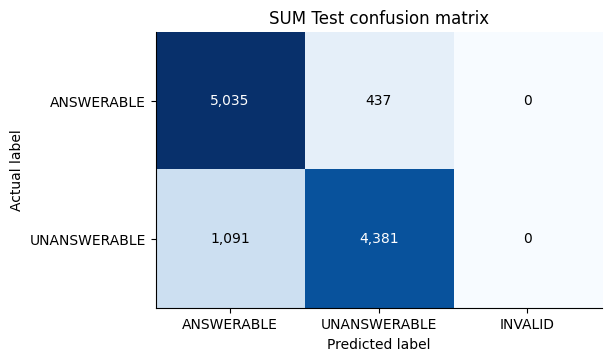

,Actual examples,Correct,Wrong label,INVALID,Wrong-label rate,Total error rate
Actual class,,,,,,
ANSWERABLE,5472,5035,437,0,7.99%,7.99%
UNANSWERABLE,5472,4381,1091,0,19.94%,19.94%


There were **437 false positives** (7.99% of answerable questions) and **1,091 false negatives** (19.94% of unanswerable questions). Of the true UNANSWERABLE rows, 0 additionally received INVALID responses and count as missed positives in recall.

,Row index,Pair ID,Question,Actual label,Prediction,Raw response (repr),Hit token limit
Error type,,,,,,,
False positive,16,6519,Two dice appear to be normal dice with their f...,ANSWERABLE,UNANSWERABLE,'UNANSWERABLE',False
False negative,6,13331,"Simplify first, then evaluate: \(\left(\frac{2...",UNANSWERABLE,ANSWERABLE,'ANSWERABLE',False


**Categories with no recorded examples:** INVALID.

In [4]:
show_evaluation('SUM Test', sum_metrics, sum_matrix)
show_class_errors(sum_matrix)
display(Markdown(interpret_errors(sum_matrix)))
show_examples(sum_predictions, 'pair_id')


## 4. UMWP Results & Analysis

UMWP is an external mathematical word problem benchmark. The analysis uses the complete saved UMWP run.

The examples use the same selection rule as SUM Test.

,Examples,Accuracy,Precision (UNANSWERABLE),Recall (UNANSWERABLE),F1 (UNANSWERABLE),Invalid outputs
Dataset,,,,,,
UMWP,"5,200",0.924231,0.951679,0.893846,0.921856,0 (0.00%)


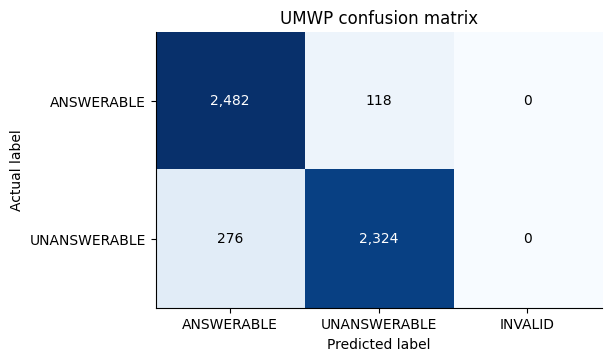

,Actual examples,Correct,Wrong label,INVALID,Wrong-label rate,Total error rate
Actual class,,,,,,
ANSWERABLE,2600,2482,118,0,4.54%,4.54%
UNANSWERABLE,2600,2324,276,0,10.62%,10.62%


There were **118 false positives** (4.54% of answerable questions) and **276 false negatives** (10.62% of unanswerable questions). Of the true UNANSWERABLE rows, 0 additionally received INVALID responses and count as missed positives in recall.

,Row index,Question ID,Question,Actual label,Prediction,Raw response (repr),Hit token limit
Error type,,,,,,,
False positive,18,19,Matthew gave equal numbers of crackers and cak...,ANSWERABLE,UNANSWERABLE,'UNANSWERABLE',False
False negative,2609,2510,Bobby ate -23 pieces of candy. If he initially...,UNANSWERABLE,ANSWERABLE,'ANSWERABLE',False


**Categories with no recorded examples:** INVALID.

In [5]:
show_evaluation('UMWP', umwp_metrics, umwp_matrix)
show_class_errors(umwp_matrix)
display(Markdown(interpret_errors(umwp_matrix)))
show_examples(umwp_predictions, 'id')


## 5. Dataset Comparison & Interpretation

Rates use each dataset's full run as the denominator for accuracy, INVALID rate, and prediction shares. Precision, recall and F1 use the UNANSWERABLE class. The metric chart shows INVALID separately because its scale is much smaller.

,ANSWERABLE,UNANSWERABLE,INVALID
Dataset,,,
SUM Test,6126 (55.98%),4818 (44.02%),0 (0.00%)
UMWP,2758 (53.04%),2442 (46.96%),0 (0.00%)


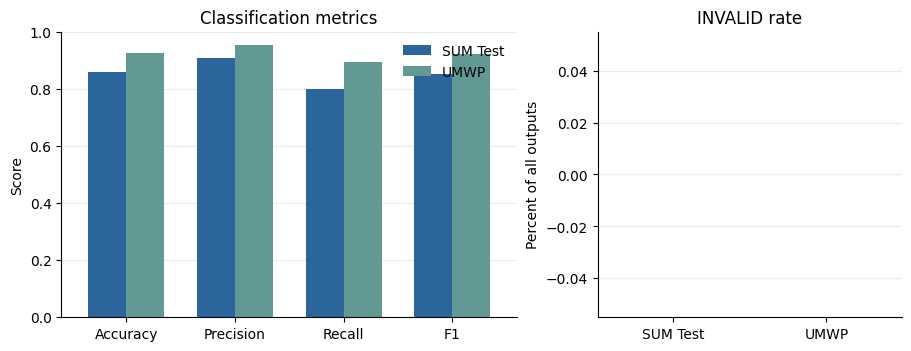

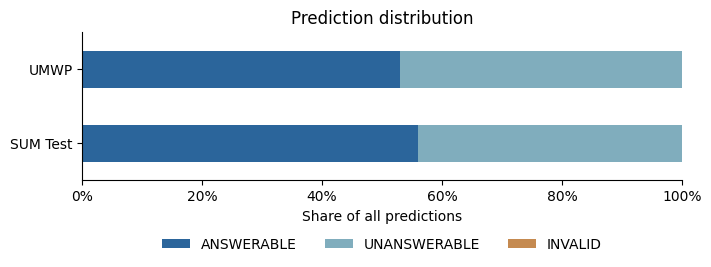

In [6]:
evaluations = {'SUM Test': (sum_metrics, sum_matrix), 'UMWP': (umwp_metrics, umwp_matrix)}
metric_rates = pd.DataFrame({
    name: {label: metrics[key] for label, key in METRICS.items()}
    for name, (metrics, _) in evaluations.items()
})
metric_rates.index = ['Accuracy', 'Precision', 'Recall', 'F1']
invalid_rates = pd.Series({name: metrics['invalid_rate'] for name, (metrics, _) in evaluations.items()})
prediction_counts = pd.DataFrame({
    name: matrix.sum(axis=0) for name, (_, matrix) in evaluations.items()
}).T
prediction_shares = prediction_counts.div(prediction_counts.sum(axis=1), axis=0)
display((prediction_counts.astype(str) + ' (' + prediction_shares.map('{:.2%}'.format) + ')')
        .rename_axis('Dataset'))

colors = ['#2b659b', '#629995']
fig, (ax_metrics, ax_invalid) = plt.subplots(
    1, 2, figsize=(9, 3.4), width_ratios=[3, 2], layout='constrained',
)
metric_rates.plot.bar(ax=ax_metrics, color=colors, rot=0, width=0.7)
ax_metrics.set(ylim=(0, 1), ylabel='Score', title='Classification metrics')
ax_metrics.legend(frameon=False, loc='upper right')
ax_invalid.bar(invalid_rates.index, invalid_rates * 100, color=colors)
ax_invalid.set(ylabel='Percent of all outputs', title='INVALID rate')
for ax in (ax_metrics, ax_invalid):
    ax.set_axisbelow(True)
    ax.grid(axis='y', alpha=0.25)
plt.show()
plt.close(fig)

fig, ax = plt.subplots(figsize=(7, 2.5), layout='constrained')
prediction_shares.plot.barh(ax=ax, stacked=True, color=['#2b659b', '#80adbd', '#c58a50'])
ax.set(xlim=(0, 1), xlabel='Share of all predictions', ylabel='', title='Prediction distribution')
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(xmax=1))
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.3), ncol=3, frameon=False)
plt.show()
plt.close(fig)

In [7]:
observations = []
for name, (metrics, matrix) in evaluations.items():
    actual_share = matrix.loc['UNANSWERABLE'].sum() / matrix.values.sum()
    predicted_share = prediction_shares.loc[name, 'UNANSWERABLE']
    precision = metrics['precision_unanswerable']
    recall = metrics['recall_unanswerable']
    fp = matrix.loc['ANSWERABLE', 'UNANSWERABLE']
    fn = matrix.loc['UNANSWERABLE', 'ANSWERABLE']
    observations.append(
        f'On {name}, **{predicted_share:.2%}** of outputs were UNANSWERABLE '
        f'against an actual UNANSWERABLE share of {actual_share:.2%}. '
        f'Precision was **{precision:.2%}** and recall was **{recall:.2%}**, '
        f'with {fp:,} false positives and {fn:,} false negatives.'
    )
precision_gap = (umwp_metrics['precision_unanswerable'] - sum_metrics['precision_unanswerable']) * 100
recall_gap = (umwp_metrics['recall_unanswerable'] - sum_metrics['recall_unanswerable']) * 100
display(Markdown(
    ' '.join(observations) + ' Relative to SUM Test, UMWP changed UNANSWERABLE '
    f'precision by {precision_gap:+.2f} percentage points and recall by '
    f'{recall_gap:+.2f} percentage points. '
    'These differences describe the saved runs under the recorded prompt and decoding settings.'
))

On SUM Test, **44.02%** of outputs were UNANSWERABLE against an actual UNANSWERABLE share of 50.00%. Precision was **90.93%** and recall was **80.06%**, with 437 false positives and 1,091 false negatives. On UMWP, **46.96%** of outputs were UNANSWERABLE against an actual UNANSWERABLE share of 50.00%. Precision was **95.17%** and recall was **89.38%**, with 118 false positives and 276 false negatives. Relative to SUM Test, UMWP changed UNANSWERABLE precision by +4.24 percentage points and recall by +9.32 percentage points. These differences describe the saved runs under the recorded prompt and decoding settings.

## 6. API Token Usage & Estimated Cost

Usage comes from each completed run's `run_metadata.json`. The estimates use the saved pricing assumptions and recorded API token counts. Actual billing may differ.

In [8]:
usage = pd.DataFrame.from_dict({
    name: {
        'Requests': record['usage']['completed_requests'],
        'Attempts': record['usage']['request_attempts'],
        'Input tokens': record['usage']['input_tokens'],
        'Cached input tokens': record['usage']['cached_input_tokens'],
        'Output tokens': record['usage']['output_tokens'],
        'Total tokens': record['usage']['total_tokens'],
        'Responses missing usage': record['usage']['responses_without_usage'],
        'Estimated cost (USD)': record['usage']['estimated_cost_usd'],
    }
    for name, record in metadata.items()
}, orient='index').rename_axis('Dataset')

combined = usage.sum(axis=0, skipna=False)
summary = pd.concat([usage, combined.to_frame().T.rename(index={0: 'Combined'})]).rename_axis('Dataset')
summary['Estimated cost (USD)'] = summary['Estimated cost (USD)'].map(
    lambda cost: f'${cost:.6f}' if pd.notna(cost) else 'Unavailable',
)
for column in summary.columns.drop('Estimated cost (USD)'):
    summary[column] = summary[column].map('{:,.0f}'.format)
display(summary)

prices = run['prices_usd_per_million']
display(Markdown(
    f'**Recorded rates ({run["pricing_verified_date"]}, USD per million tokens).** '
    f'Input ${prices["input"]:.2f}, cached input ${prices["cached_input"]:.2f}, '
    f'output ${prices["output"]:.2f}.'
))

,Requests,Attempts,Input tokens,Cached input tokens,Output tokens,Total tokens,Responses missing usage,Estimated cost (USD)
Dataset,,,,,,,,
SUM Test,"10,944","10,944","1,241,573",0,"59,538","1,301,111",0,$1.539263
UMWP,"5,200","5,200","506,868",0,"28,442","535,310",0,$0.649078
Combined,"16,144","16,144","1,748,441",0,"87,980","1,836,421",0,$2.188341


**Recorded rates (2026-11-22, USD per million tokens).** Input $1.00, cached input $0.05, output $5.00.

## 7. Conclusion

In [9]:
accuracy_gap = 100 * (umwp_metrics['accuracy'] - sum_metrics['accuracy'])
f1_gap = 100 * (umwp_metrics['f1_unanswerable'] - sum_metrics['f1_unanswerable'])
display(Markdown(
    f"**SUM Test** achieved {sum_metrics['accuracy']:.2%} accuracy and "
    f"{sum_metrics['f1_unanswerable']:.2%} UNANSWERABLE F1, with {sum_metrics['num_invalid']:,} INVALID responses. "
    f"**UMWP** achieved {umwp_metrics['accuracy']:.2%} accuracy and "
    f"{umwp_metrics['f1_unanswerable']:.2%} UNANSWERABLE F1, with {umwp_metrics['num_invalid']:,} INVALID responses. "
    f"UMWP scored {accuracy_gap:.2f} percentage points higher in accuracy and "
    f"{f1_gap:.2f} points higher in UNANSWERABLE F1."
))

**SUM Test** achieved 86.04% accuracy and 85.15% UNANSWERABLE F1, with 0 INVALID responses. **UMWP** achieved 92.42% accuracy and 92.19% UNANSWERABLE F1, with 0 INVALID responses. UMWP scored 6.39 percentage points higher in accuracy and 7.04 points higher in UNANSWERABLE F1.